# Parallel (associative-scan) solvers

The Riccati recursion in LQR is sequential: step $t$ needs step $t+1$. However, the recursion can
be rewritten as an **associative** combination of per-step elements, which
`jax.lax.associative_scan` evaluates in $O(\log T)$ parallel depth (Särkkä & García-Fernández,
2023). diffilqrax provides parallel counterparts of every solver:

| sequential | parallel |
|---|---|
| `lqr.solve_lqr` | `plqr.solve_plqr` |
| `ilqr.ilqr_solver` | `parallel_ilqr.pilqr_solver` |
| `diff_lqr.dlqr` | `parallel_dlqr.pdlqr` |
| `diff_ilqr.dilqr` | `parallel_dilqr.pdilqr` |

The parallel versions take the same arguments and converge to the same solutions. This notebook
checks that on a long-horizon iLQR problem and shows how run time scales with the horizon.

The parallel solvers do more total work, so on a **CPU** you should not expect a speed-up; at
best they roughly match the sequential solver. The benefit appears on a **GPU** with long
horizons, where the sequential solver is limited by its $O(T)$ depth.

In [1]:
import time as timer

import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt

from diffilqrax.ilqr import ilqr_solver
from diffilqrax.parallel_ilqr import pilqr_solver, dynamics_defects
from diffilqrax.diff_ilqr import dilqr
from diffilqrax.parallel_dilqr import pdilqr
from diffilqrax.typs import System, ModelDims, iLQRParams, Theta

jax.config.update("jax_enable_x64", True)
print("device:", jax.devices()[0])

device: TFRT_CPU_0


## A long-horizon problem

A stable tanh RNN, $x_{t+1} = \tanh(U_h x_t + W_h u_t)$, tracks a slow sine wave in every state.

In [2]:
N, M = 8, 3
k1, k2 = jr.split(jr.PRNGKey(0))
theta = Theta(Uh=0.8 * jr.normal(k1, (N, N)) / jnp.sqrt(N), Wh=jr.normal(k2, (N, M)) / jnp.sqrt(N), sigma=0.0, Q=None)


def make_model(horizon):
    def cost(t, x, u, th):
        return jnp.sum((x - 0.5 * jnp.sin(t / 50.0)) ** 2) + 0.1 * jnp.sum(u**2)

    def costf(x, th):
        return jnp.sum(x**2)

    def dynamics(t, x, u, th):
        return jnp.tanh(th.Uh @ x + th.Wh @ u)

    return System(cost, costf, dynamics, ModelDims(n=N, m=M, horizon=horizon, dt=0.1))


params = iLQRParams(x0=jnp.zeros(N), theta=theta)

## Same solution

`pilqr_solver` has two ways to roll out a candidate step:

- `rollout="feedback"` (default) runs the parallel Riccati scan, then a sequential non-linear
  rollout under the feedback policy, exactly like `ilqr_solver`. Every iterate is a feasible
  trajectory.
- `rollout="parallel"` uses **multiple shooting**. The states are also optimisation variables, the
  dynamics defects $d_t = f(x_t, u_t) - x_{t+1}$ enter the local LQR, and the whole step is
  computed with associative scans. Iterates are feasible only at convergence, so we report the
  largest defect.

In [3]:
T = 1000
model = make_model(T)
Us_init = jnp.zeros((T, M))

(Xs, Us, _), J, _ = ilqr_solver(model, params, Us_init, max_iter=200)
(Xf, Uf, _), Jf, _ = pilqr_solver(model, params, Us_init, max_iter=200, rollout="feedback")
(Xp, Up, _), Jp, _ = pilqr_solver(model, params, Us_init, max_iter=200, rollout="parallel")

print(f"ilqr             J = {float(J):.10f}")
print(f"pilqr feedback   J = {float(Jf):.10f}   max|ΔU| = {jnp.max(jnp.abs(Uf - Us)):.1e}")
print(f"pilqr parallel   J = {float(Jp):.10f}   max|ΔU| = {jnp.max(jnp.abs(Up - Us)):.1e}   "
      f"max defect = {jnp.max(jnp.abs(dynamics_defects(model, params, Xp, Up))):.1e}")

ilqr             J = 745.6031498673
pilqr feedback   J = 745.6031498673   max|ΔU| = 1.2e-15


pilqr parallel   J = 745.6031498673   max|ΔU| = 7.0e-13   max defect = 3.3e-16


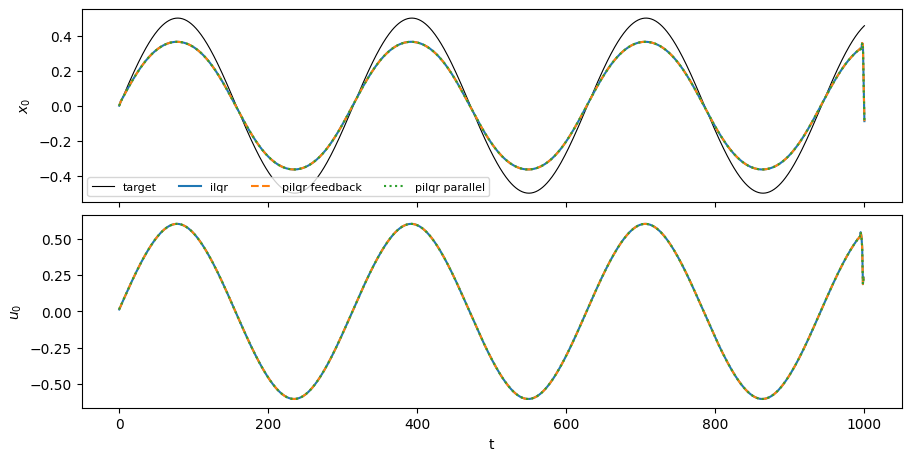

In [4]:
time = jnp.arange(T + 1)
fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True, layout="constrained")
axes[0].plot(time, 0.5 * jnp.sin(time / 50.0), "k", lw=0.8, label="target")
for (X, U), style, label in [((Xs, Us), "-", "ilqr"), ((Xf, Uf), "--", "pilqr feedback"), ((Xp, Up), ":", "pilqr parallel")]:
    axes[0].plot(time, X[:, 0], style, label=label)
    axes[1].plot(time[:-1], U[:, 0], style)
axes[0].set(ylabel="$x_0$")
axes[1].set(ylabel="$u_0$", xlabel="t")
axes[0].legend(ncol=4, fontsize=8);

## Gradients agree too

`pdilqr` is the parallel counterpart of `dilqr`. Both the forward solve and the adjoint LQR in the
reverse pass use associative scans.

In [5]:
Ts = 200
model_s = make_model(Ts)
U0 = jnp.zeros((Ts, M))


def loss(solver, th):
    return jnp.sum(solver(model_s, iLQRParams(params.x0, th), U0, max_iter=200) ** 2)


g_seq = jax.grad(lambda th: loss(dilqr, th))(theta)
g_par = jax.grad(lambda th: loss(pdilqr, th))(theta)
for name in ("Uh", "Wh"):
    a, b = getattr(g_par, name), getattr(g_seq, name)
    print(f"dL/d{name}: relative difference {jnp.linalg.norm(a - b) / jnp.linalg.norm(b):.1e}")

dL/dUh: relative difference 9.8e-15
dL/dWh: relative difference 7.1e-15


## Scaling with the horizon

We time one jitted solve at several horizons. The absolute numbers depend on your hardware. On a
CPU, all three scale linearly and take similar time. On a GPU, the `"parallel"` rollout should
scale best.

In [6]:
def time_solver(solve, model, n_repeat=3):
    Us0 = jnp.zeros((model.dims.horizon, M))
    f = jax.jit(lambda p, u: solve(model, p, u, max_iter=200))
    jax.block_until_ready(f(params, Us0))  # compile
    start = timer.perf_counter()
    for _ in range(n_repeat):
        jax.block_until_ready(f(params, Us0))
    return (timer.perf_counter() - start) / n_repeat


solvers = {
    "ilqr": ilqr_solver,
    "pilqr feedback": lambda m, p, u, **kw: pilqr_solver(m, p, u, rollout="feedback", **kw),
    "pilqr parallel": lambda m, p, u, **kw: pilqr_solver(m, p, u, rollout="parallel", **kw),
}
horizons = [250, 500, 1000, 2000]
timings = {name: [time_solver(s, make_model(h)) for h in horizons] for name, s in solvers.items()}

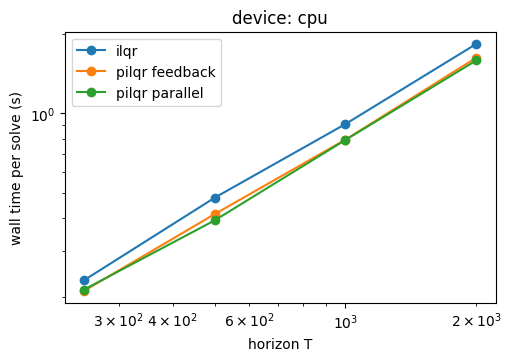

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.5), layout="constrained")
for name, ts in timings.items():
    ax.loglog(horizons, ts, "o-", label=name)
ax.set(xlabel="horizon T", ylabel="wall time per solve (s)", title=f"device: {jax.devices()[0].platform}")
ax.legend();

## How to adapt

- **Switching solver:** replace `ilqr_solver` with `pilqr_solver` (or `dilqr` with `pdilqr`). The
  model, parameters and initial inputs are unchanged.
- **Choosing a rollout:** use `"feedback"` when you need every iterate to be feasible, for example
  when stopping early. Use `"parallel"` for the most parallelism on a GPU.
- **Non-convex costs:** `make_psd="R"` or `"full"` projects the local problem to be convex, which
  makes every scan element valid without regularisation retries.
- **Gradient adjoint:** `pdilqr(..., adjoint="sequential")` solves the reverse LQR sequentially.
  This is useful for checking results or on a CPU.
- **Benchmarking on a GPU:** install a CUDA build of JAX and re-run this notebook. For a script
  version, see `examples/long_horizon.py` in the repository.